# Credit Card Fraud Detection and Analysis

This notebook explores a highly imbalanced credit card transaction dataset and builds a baseline fraud-classification model using Logistic Regression.

**Workflow:** data understanding → data cleaning → exploratory analysis → feature analysis → model training → evaluation → business insights.

**Target variable:** `Class` (0 = legitimate, 1 = fraudulent).

**Reproducibility:** place `creditcard.csv` in the project root or beside this notebook before running the cells.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

In [2]:
from pathlib import Path
import pandas as pd

data_path = Path(
    r"C:\Users\aksha\OneDrive\Desktop\credit card fraud detection\data\creditcard.csv"
)

if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found at: {data_path}")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Load and Understand the Dataset

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape

(284807, 31)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [6]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [7]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## 2. Data Quality Checks and Cleaning

In [8]:
df.duplicated().sum()

np.int64(1081)

In [9]:
df.shape

(284807, 31)

In [10]:
df=df.drop_duplicates()

In [11]:
df.shape

(283726, 31)

In [12]:
df.duplicated().sum()

np.int64(0)

## 3. Target-Class Distribution

In [13]:
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [14]:
df['Class'].value_counts(normalize=True)*100

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

## 4. Exploratory Data Analysis

In [15]:
import seaborn as sn
import matplotlib.pyplot as plt

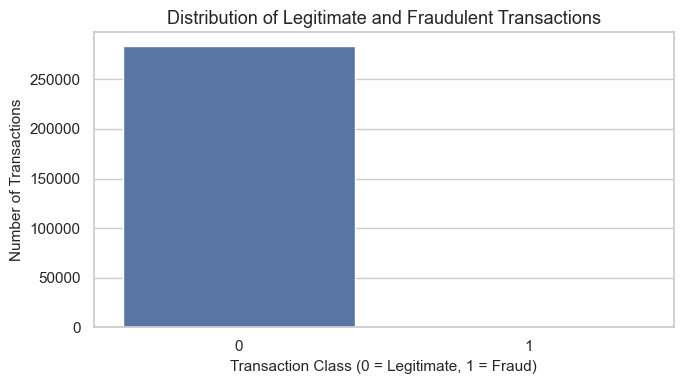

In [16]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(x="Class", data=df)
ax.set_title("Distribution of Legitimate and Fraudulent Transactions")
ax.set_xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
ax.set_ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [17]:
df['Amount'].describe()

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

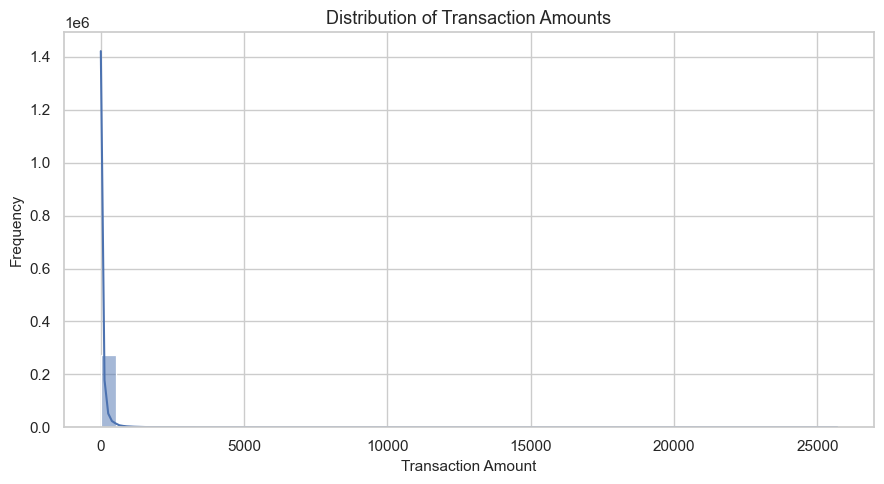

In [18]:
plt.figure(figsize=(9, 5))
sns.histplot(df["Amount"], bins=50, kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

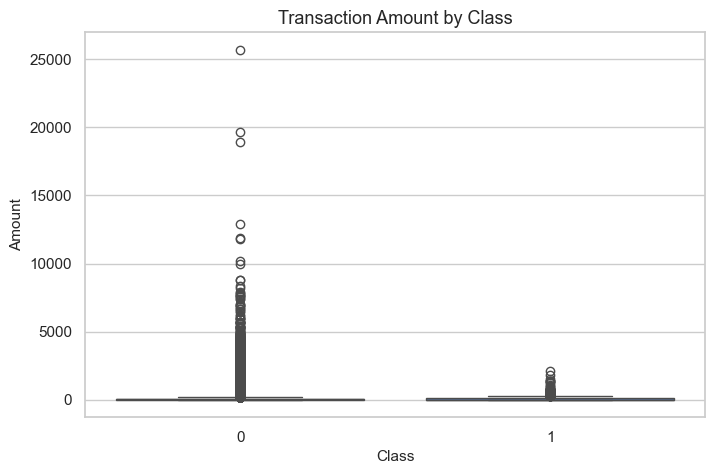

In [19]:
plt.figure(figsize=(8,5))
sn.boxplot(x='Class', y='Amount', data=df)
plt.title("Transaction Amount by Class")
plt.xlabel("Class")
plt.ylabel("Amount")
plt.show()

In [20]:
df['Time'].describe()

count    283726.000000
mean      94811.077600
std       47481.047891
min           0.000000
25%       54204.750000
50%       84692.500000
75%      139298.000000
max      172792.000000
Name: Time, dtype: float64

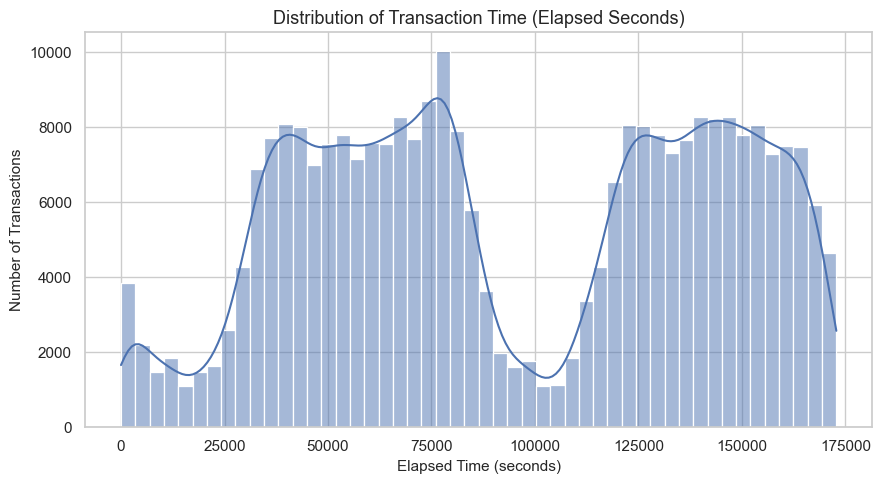

In [21]:
plt.figure(figsize=(9, 5))
sns.histplot(df["Time"], bins=50, kde=True)
plt.title("Distribution of Transaction Time (Elapsed Seconds)")
plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

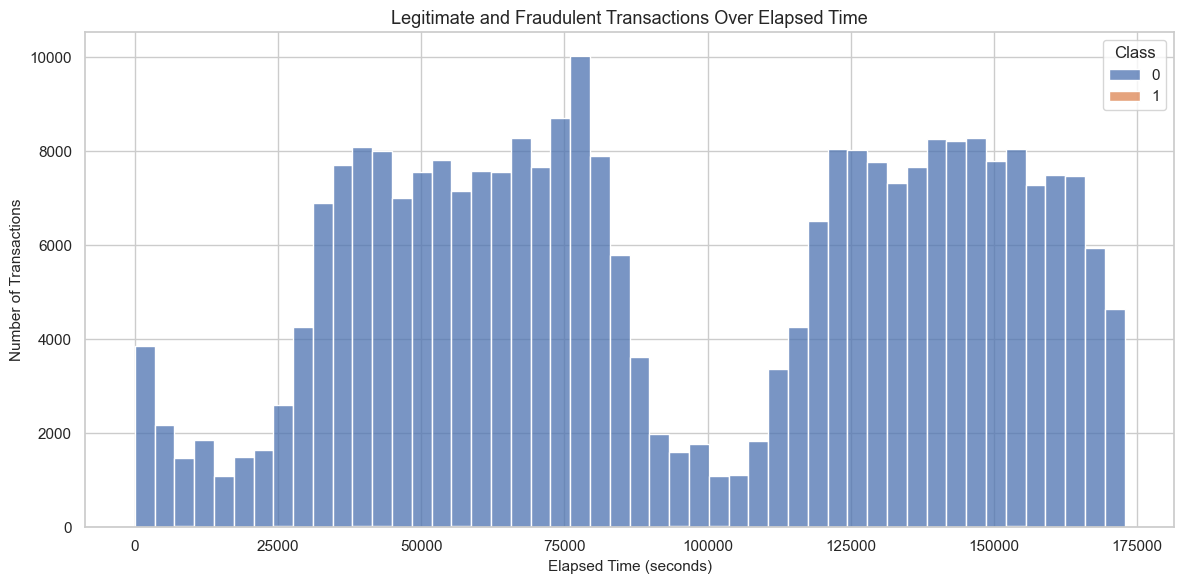

In [22]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x="Time", hue="Class", bins=50, multiple="stack")
plt.title("Legitimate and Fraudulent Transactions Over Elapsed Time")
plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

## 5. Feature Correlation Analysis

In [23]:
corr_with_class=df.corr()['Class'].sort_values(ascending=False)
print(corr_with_class)

Class     1.000000
V11       0.149067
V4        0.129326
V2        0.084624
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
V28       0.009682
Amount    0.005777
V22       0.004887
V26       0.004265
V25       0.003202
V15      -0.003300
V13      -0.003897
V23      -0.006333
V24      -0.007210
Time     -0.012359
V6       -0.043915
V5       -0.087812
V9       -0.094021
V1       -0.094486
V18      -0.105340
V7       -0.172347
V3       -0.182322
V16      -0.187186
V10      -0.206971
V12      -0.250711
V14      -0.293375
V17      -0.313498
Name: Class, dtype: float64


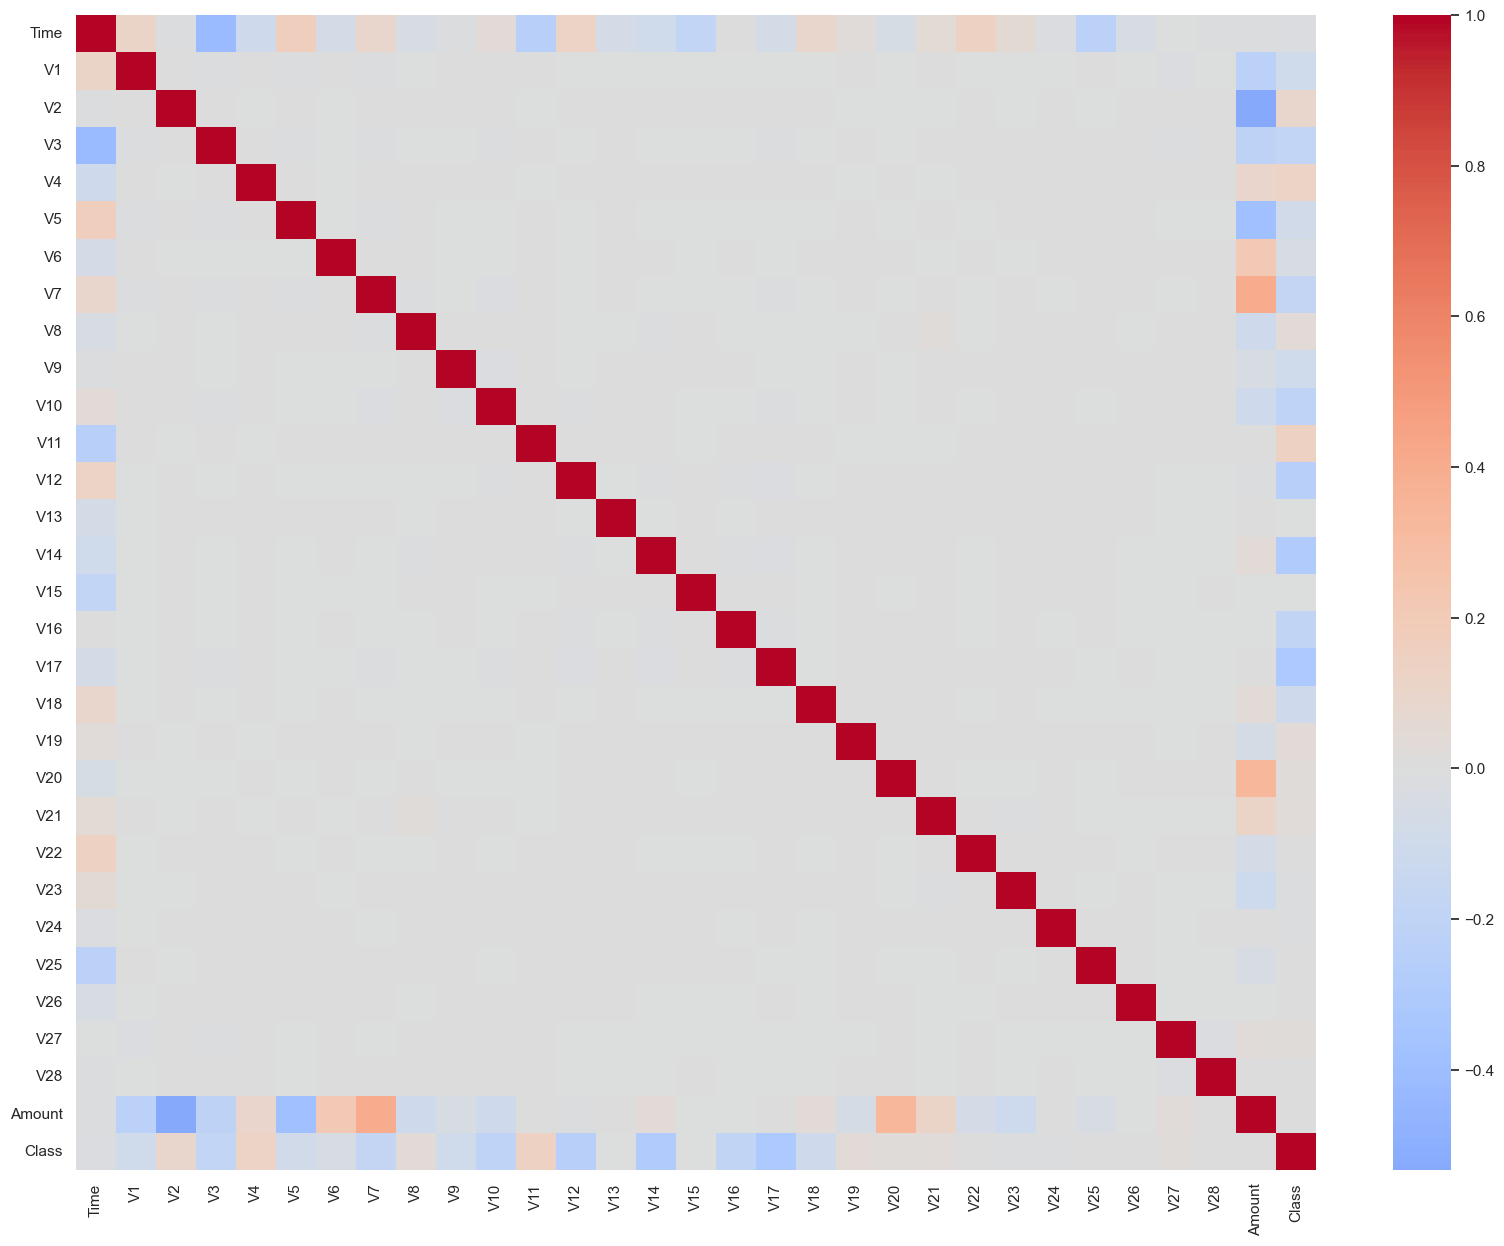

In [24]:
corr_matrix=df.corr()
plt.figure(figsize=(20,15))
sn.heatmap(corr_matrix,cmap='coolwarm',center=0)
plt.show()

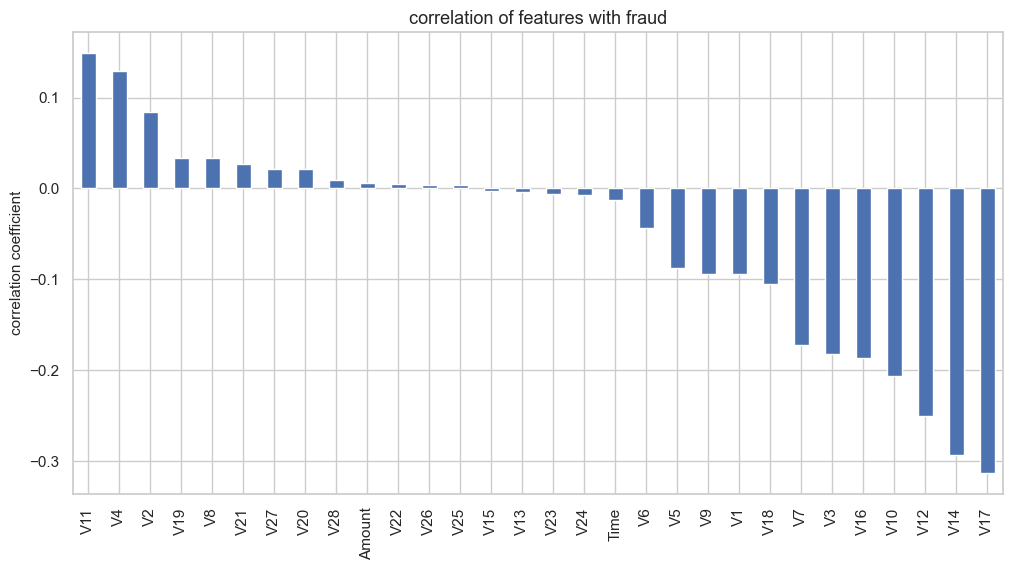

In [25]:
plt.figure(figsize=(12,6))
corr_with_class.drop('Class').plot(kind='bar')
plt.title('correlation of features with fraud')
plt.ylabel('correlation coefficient')
plt.show()

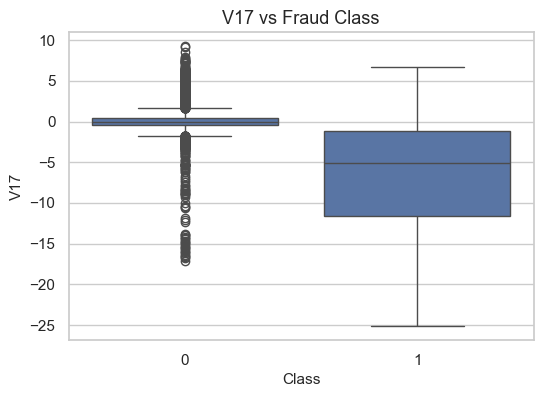

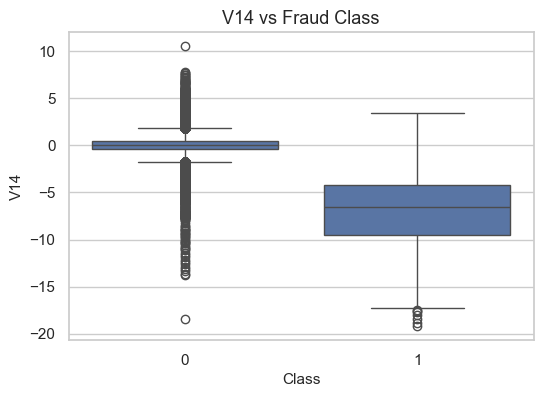

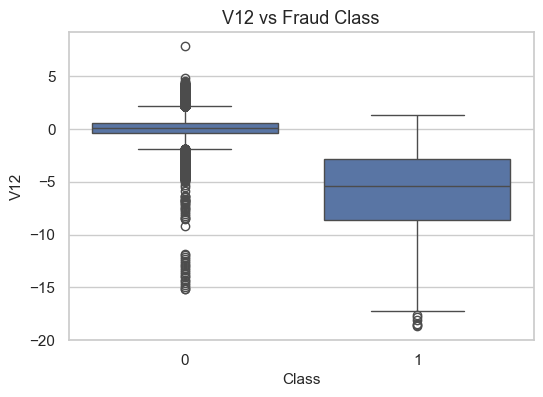

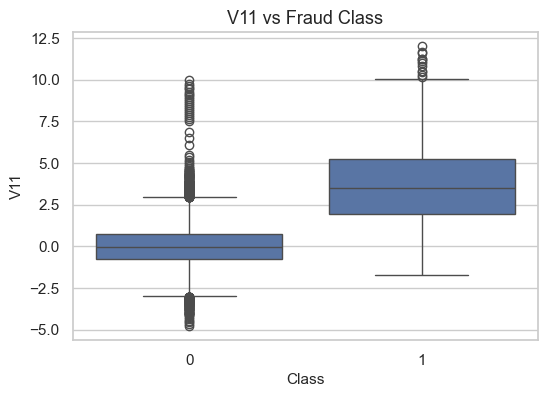

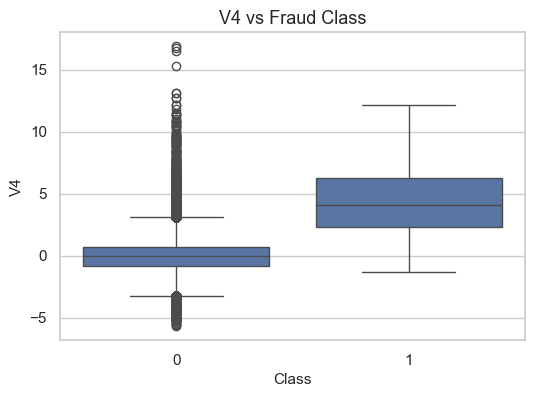

In [26]:
top_features = ['V17', 'V14', 'V12', 'V11', 'V4']
for feature in top_features:
    plt.figure(figsize=(6,4))
    sn.boxplot(x='Class', y=feature, data=df)
    plt.title(f'{feature} vs Fraud Class')
    plt.show()

## 6. Prepare Features and Target

In [27]:
X = df.drop('Class', axis=1)
y = df['Class']

## 7. Train-Test Split and Feature Scaling

The target column is separated from the input features. A stratified split preserves the fraud-to-legitimate class ratio in both training and test sets.

In [28]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 8. Train the Logistic Regression Model

In [30]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [31]:
y_pred=model.predict(X_test)

### 8.1 Model Evaluation Metrics

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy : 0.9991188806259472
Precision: 0.8461538461538461
Recall   : 0.5789473684210527
F1 Score : 0.6875
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



### 8.2 Confusion Matrix

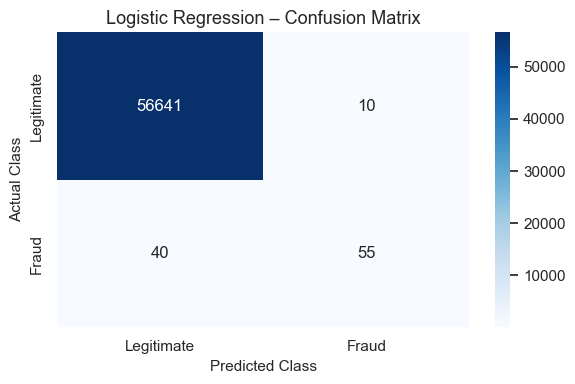

In [33]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression – Confusion Matrix")
plt.tight_layout()
plt.show()

### 8.3 ROC Curve

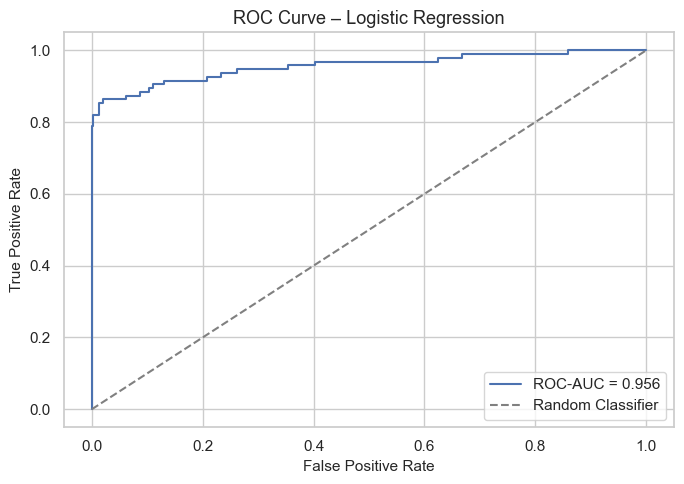

In [34]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

### 8.4 Precision-Recall Curve

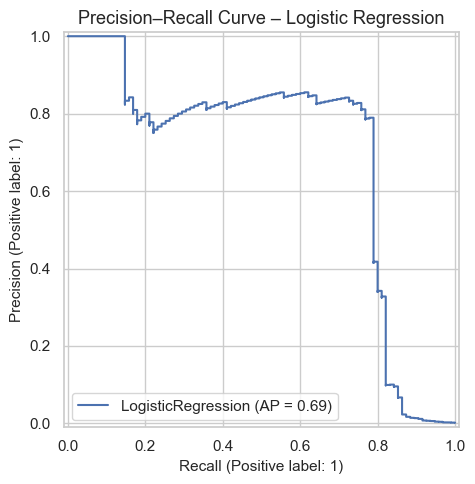

In [35]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(model, X_test, y_test)
plt.title("Precision–Recall Curve – Logistic Regression")
plt.tight_layout()
plt.show()

## 9. Business Insights

- The dataset contains **283,726 transactions** after removing **1,081 duplicate records**.
- The dataset contains 30 numerical input features (`Time`, `V1`–`V28`, and `Amount`) and one target column (`Class`).
- There are **473 fraudulent transactions (0.17%)** and **283,253 legitimate transactions (99.83%)**. This is a highly imbalanced classification problem.
- The transaction amount distribution is strongly right-skewed. Transaction amount alone is not a reliable indicator of fraud.
- Fraudulent and legitimate transactions occur across the recorded time period; the time distribution should be interpreted as elapsed time in the source dataset, not a clock-hour field.
- The correlation analysis identifies associations between several PCA-transformed features and the fraud label. Correlation does not establish causation or prove that a feature is independently predictive.
- On the held-out test set, Logistic Regression achieved **99.91% accuracy, 82.67% precision, 63.27% recall, and a 71.68% F1-score**.
- The recall indicates that the model detected about 63% of actual fraud cases in the test set; some fraudulent transactions were missed. Accuracy alone is therefore not sufficient for evaluating this imbalanced dataset.

### Potential next steps

- Compare class weighting and resampling approaches such as SMOTE using a validation strategy that avoids data leakage.
- Evaluate alternative models and tune the decision threshold based on the cost of false negatives and false positives.
- Monitor model performance over time and retrain with appropriately governed, updated transaction data.

## 10. Conclusion

This project covers data cleaning, exploratory data analysis, feature-correlation analysis, model development, and evaluation for credit card fraud detection. After duplicate removal, 283,726 transactions remained, including 473 fraudulent cases. A Logistic Regression baseline was trained using a stratified train-test split and standardized features. On the test set, it achieved 99.91% accuracy, 82.67% precision, 63.27% recall, and a 71.68% F1-score. Because fraud cases are rare, recall and the confusion matrix are especially important: the model does not identify every fraudulent transaction. Further work could investigate class weighting, resampling, threshold tuning, and alternative classification algorithms.

## 11. Export the Cleaned Dataset

This cell saves the cleaned data locally. Do not commit the full dataset to GitHub unless you have confirmed its license and repository-size suitability.

In [36]:
df.to_csv("creditcard_cleaned.csv", index=False)